In [2]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

splits = ["train", "test", "contrast", "gaussian_noise", "impulse_noise",
          "jpeg_compression", "motion_blur", "pixelate", "spatter"]
ds = load_dataset("parquet", data_files={s: f"data/{s}-00000-of-00001.parquet" for s in splits})
print(ds)
print(ds["train"].features)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 26640
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    contrast: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    gaussian_noise: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    impulse_noise: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    jpeg_compression: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    motion_blur: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    pixelate: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
    spatter: Dataset({
        features: ['image', 'label'],
        num_rows: 12630
    })
})
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['red and white circle 20 kph speed limit', 'red and white circle

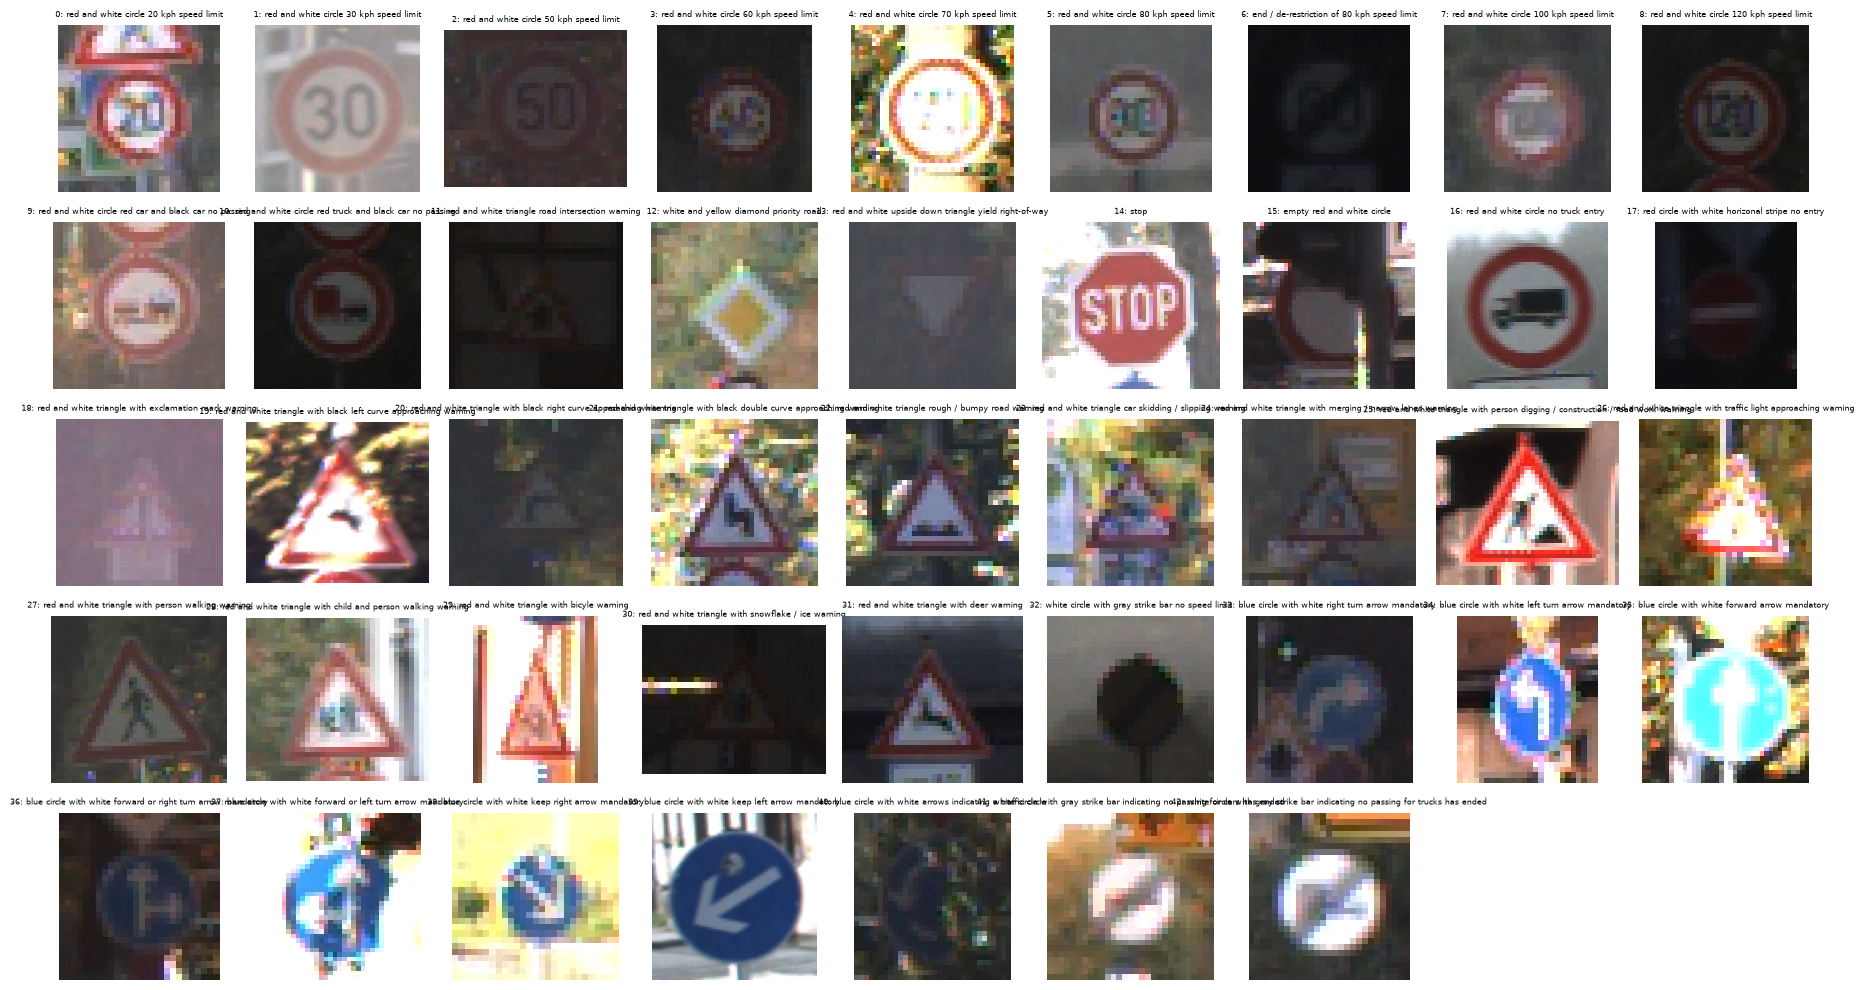

In [4]:
labels = np.array(ds["train"]["label"])
class_names = ds["train"].features["label"].names   # list of 43 names, fetched once

fig, axes = plt.subplots(5, 9, figsize=(18, 10))
axes = axes.flatten()

for c in range(43):
    idx = np.where(labels == c)[0][0]    # index of the first image of class c
    img = ds["train"][idx]["image"]      # the image itself
    axes[c].imshow(img)
    axes[c].set_title(f"{c}: {class_names[c]}", fontsize=6)
    axes[c].axis("off")

for ax in axes[43:]:                     # hide the 2 empty slots
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/class_examples.png", dpi=200, bbox_inches="tight")
plt.show()

train min: 150 class 0 | max: 1500 class 1
test min: 60 class 0 | max: 750 class 2


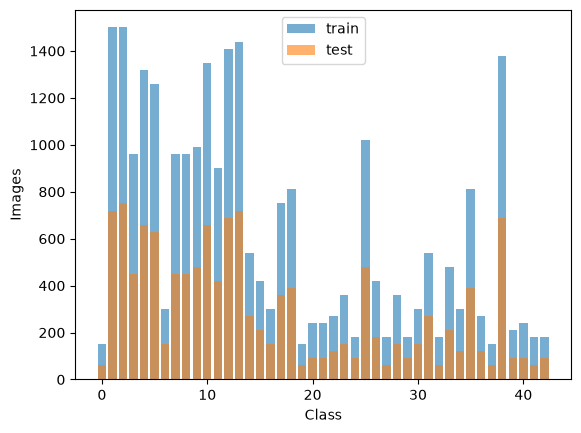

In [5]:
for s in ["train", "test"]:
    counts = np.bincount(np.array(ds[s]["label"]), minlength=43)
    plt.bar(range(43), counts, alpha=0.6, label=s)
    print(s, "min:", counts.min(), "class", counts.argmin(), "| max:", counts.max(), "class", counts.argmax())
plt.xlabel("Class"); plt.ylabel("Images"); plt.legend()
plt.savefig("figures/class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

Width median: 43.0 min: 25 max: 243
Height median: 43.0 min: 25 max: 225


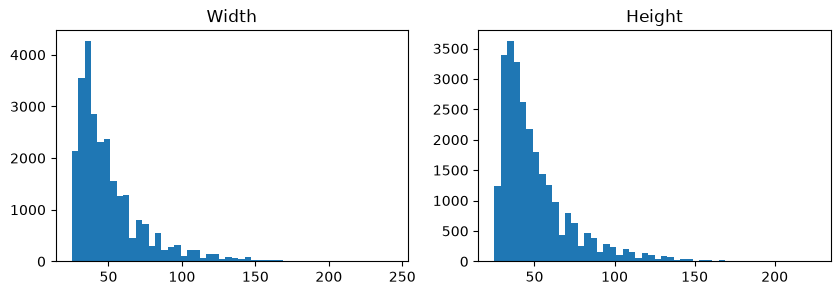

In [6]:
sizes = np.array([img.size for img in ds["train"]["image"]])  # (width, height)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for i, name in enumerate(["Width", "Height"]):
    ax[i].hist(sizes[:, i], bins=50); ax[i].set_title(name)
    print(name, "median:", np.median(sizes[:, i]), "min:", sizes[:, i].min(), "max:", sizes[:, i].max())
plt.savefig("figures/image_sizes.png", dpi=200, bbox_inches="tight")
plt.show()

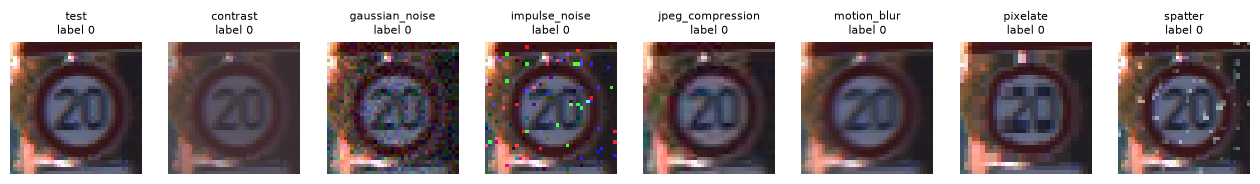

In [14]:
i = 0  # try 2–3 different indices, e.g. 100, 5000
fig, ax = plt.subplots(1, 8, figsize=(16, 2.5))
for a, s in zip(ax, splits[1:]):  # test + the 7 corruptions
    a.imshow(ds[s][i]["image"]); a.set_title(f"{s}\nlabel {ds[s][i]['label']}", fontsize=8); a.axis("off")
plt.savefig("figures/corruptions.png", dpi=200, bbox_inches="tight")
plt.show()

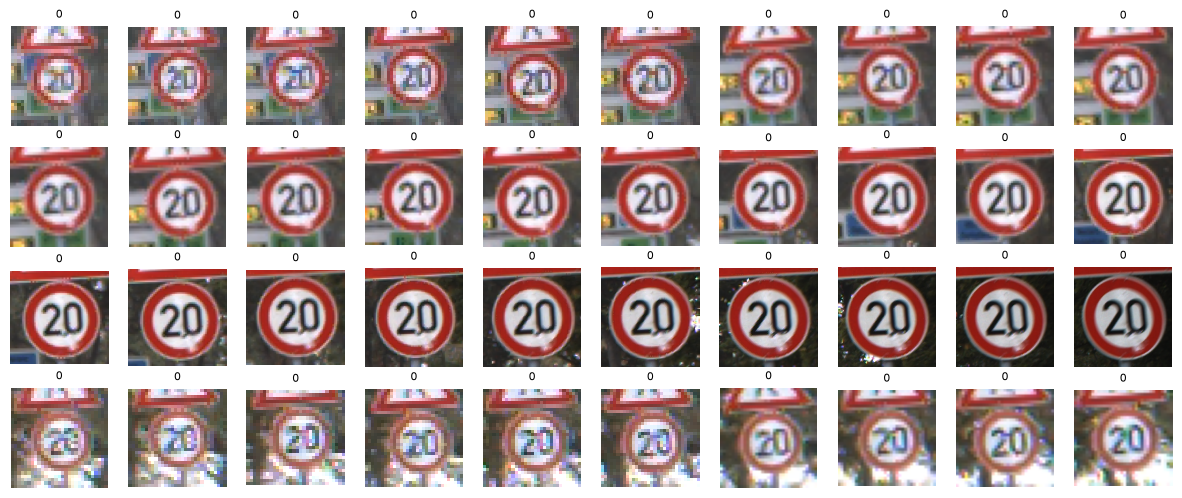

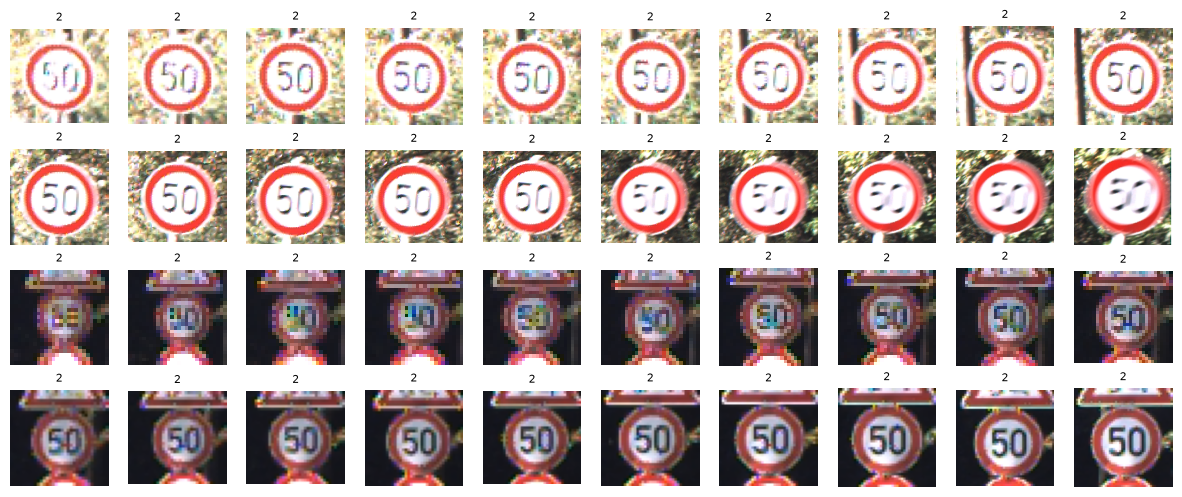

In [15]:
for start in [0, 10000]:
    fig, ax = plt.subplots(4, 10, figsize=(15, 6))
    for k, a in enumerate(ax.flat):
        a.imshow(ds["train"][start + k]["image"]); a.set_title(labels[start + k], fontsize=8); a.axis("off")
    plt.show()

In [16]:
print((labels.reshape(-1, 30) == labels[::30, None]).all())

True


22620 4020 overlap: set()
torch.Size([64, 3, 48, 48])


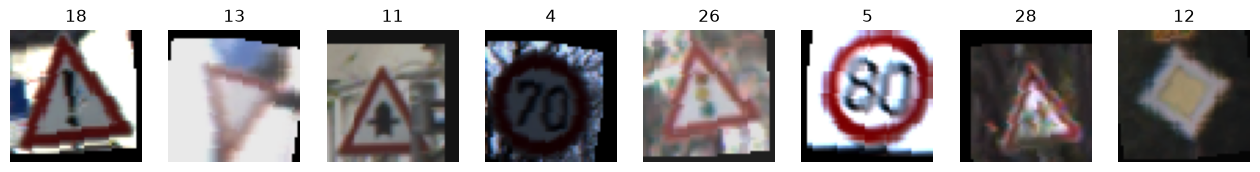

In [3]:
from data import load_gtsrb, get_loaders, track_split
ds = load_gtsrb()
tr_idx, va_idx = track_split(np.array(ds["train"]["label"]))
print(len(tr_idx), len(va_idx), "overlap:", set(tr_idx // 30) & set(va_idx // 30))

train_dl, val_dl = get_loaders(ds, size=48, augment=True)
x, y = next(iter(train_dl))
print(x.shape)
fig, ax = plt.subplots(1, 8, figsize=(16, 2.5))
for a, img, lab in zip(ax, x, y):
    a.imshow((img.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1)); a.set_title(int(lab)); a.axis("off")
plt.show()

In [4]:
import pandas as pd
for run in ["cnn_noaug", "cnn_aug"]:
    h = pd.read_csv(f"results/{run}_history.csv")
    h.plot(x="epoch", y=["train_loss", "val_loss"], title=run)
    plt.savefig(f"figures/loss_{run}.png", dpi=200, bbox_inches="tight")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'results/cnn_noaug_history.csv'

## Findings
- **Size:** train 26,640 images, test 12,630 (+ 7 corrupted versions of test, same order)
- **Imbalance:** train min: 150 class 0 | max: 1500 class 1
test min: 60 class 0 | max: 750 class 2,
ratio ≈ ___×. Test has the same/a different pattern.
- **Image size:** median 43×43 px, range 25–243 px → 48×48 for the CNN
- **Tracks:** train = 888 tracks × 30 near-identical images (track = index // 30, confirmed) → validation split by tracks
- **Similar classes:** turns being just flipped and speed limits with similar numbers liek 50/60
- **Hardest corruption (guess):** gaussian

